<a href="https://colab.research.google.com/github/RaniaChaudhry511/CODE-ALPHA-INTERNSHIP/blob/main/Task1_Credit_Scoring_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Credit Scoring Model

**CodeAlpha Machine Learning Internship**

## Objective
Predict an individual's creditworthiness, meaning the likelihood that a credit card client will default on the next payment, using past financial data.

## Approach
This is a binary classification problem. We build new features from the financial history (feature engineering), then train and compare three classification algorithms:
- Logistic Regression
- Decision Tree
- Random Forest

## Dataset
"Default of Credit Card Clients" (UCI Machine Learning Repository, also available on Kaggle). It has 30,000 credit card clients from Taiwan (April to September 2005) with 23 features: credit limit, demographics, 6 months of repayment status, bill amounts and payment amounts.
Target column: `default.payment.next.month` (1 = default, 0 = no default).

## Workflow
1. Import libraries and load the dataset
2. Explore the data
3. Clean the data
4. Feature engineering
5. Train/test split and scaling
6. Train the models
7. Evaluate using Precision, Recall, F1-Score and ROC-AUC
8. Conclusion

## Step 1: Import Libraries and Load the Dataset
In this step we import all the libraries needed for the project and load the dataset (`UCI_Credit_Card.csv`) into a pandas DataFrame. We also rename two columns for consistency: `PAY_0` becomes `PAY_1` (so the repayment columns run from `PAY_1` to `PAY_6`), and the long target name `default.payment.next.month` becomes `DEFAULT`.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)

# Upload UCI_Credit_Card.csv from your computer
from google.colab import files
uploaded = files.upload()

# Load the dataset
df = pd.read_csv('UCI_Credit_Card.csv')

# Rename columns for consistency
df = df.rename(columns={'PAY_0': 'PAY_1', 'default.payment.next.month': 'DEFAULT'})

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Saving UCI_Credit_Card.csv to UCI_Credit_Card.csv
Dataset loaded successfully!
Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


### Observation
- The dataset loaded successfully with **30,000 rows and 25 columns** (ID, 23 features and the target).
- The column renaming worked: the repayment columns now run from `PAY_1` to `PAY_6`, and the target is called `DEFAULT`.
- The `PAY_1` to `PAY_6` columns hold the repayment status for each month. Values such as -1, 0 and 2 are status codes (-1 = paid on time, positive numbers = months of delay), not amounts.
- `BILL_AMT1` to `BILL_AMT6` are monthly bill amounts and `PAY_AMT1` to `PAY_AMT6` are the payments made. These will be the base for our feature engineering.
- The `ID` column is only a row identifier, so it will be dropped later.

## Step 2: Explore the Data
Before cleaning or modeling, we check the structure of the data: column types, summary statistics, missing values, duplicate rows and the distribution of the target variable. We also look at the unique values of the categorical columns (`SEX`, `EDUCATION`, `MARRIAGE`) and the repayment status columns, because they contain coded values that we need to understand.

Shape: (30000, 25)

--- Data Types and Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         30000 non-null  int64  
 1   LIMIT_BAL  30000 non-null  float64
 2   SEX        30000 non-null  int64  
 3   EDUCATION  30000 non-null  int64  
 4   MARRIAGE   30000 non-null  int64  
 5   AGE        30000 non-null  int64  
 6   PAY_1      30000 non-null  int64  
 7   PAY_2      30000 non-null  int64  
 8   PAY_3      30000 non-null  int64  
 9   PAY_4      30000 non-null  int64  
 10  PAY_5      30000 non-null  int64  
 11  PAY_6      30000 non-null  int64  
 12  BILL_AMT1  30000 non-null  float64
 13  BILL_AMT2  30000 non-null  float64
 14  BILL_AMT3  30000 non-null  float64
 15  BILL_AMT4  30000 non-null  float64
 16  BILL_AMT5  30000 non-null  float64
 17  BILL_AMT6  30000 non-null  float64
 18  PAY_AMT1   30000 non-null  

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0



--- Missing Values ---
Total missing values: 0
Duplicate rows: 0

--- Categorical Columns (value counts) ---

SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

--- PAY_1 value counts ---
PAY_1
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

--- Target Distribution ---
DEFAULT
0    23364
1     6636
Name: count, dtype: int64
DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64


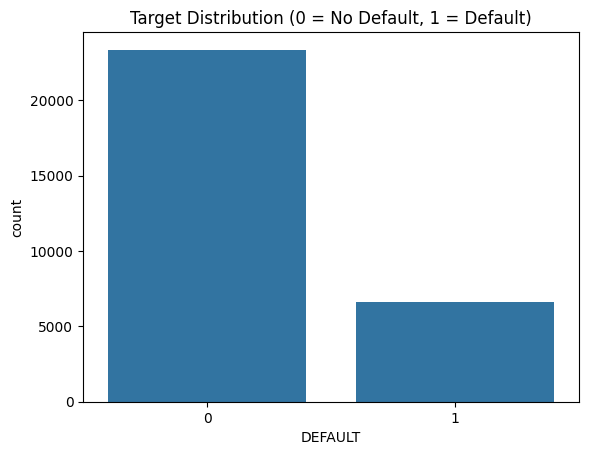

In [2]:
# Basic information
print("Shape:", df.shape)
print("\n--- Data Types and Non-Null Counts ---")
df.info()

# Summary statistics
print("\n--- Summary Statistics ---")
display(df.describe().T)

# Missing values and duplicates
print("\n--- Missing Values ---")
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Categorical columns
print("\n--- Categorical Columns (value counts) ---")
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())

# Repayment status values
print("\n--- PAY_1 value counts ---")
print(df['PAY_1'].value_counts().sort_index())

# Target distribution
print("\n--- Target Distribution ---")
print(df['DEFAULT'].value_counts())
print((df['DEFAULT'].value_counts(normalize=True) * 100).round(2))

sns.countplot(x='DEFAULT', data=df)
plt.title('Target Distribution (0 = No Default, 1 = Default)')
plt.show()

### Observation
- There are **no missing values and no duplicate rows**, so no imputation is needed.
- The target is imbalanced: **77.88% no default (23,364)** and **22.12% default (6,636)**. Because of this, accuracy alone would be misleading, and Precision, Recall, F1-Score and ROC-AUC are the right metrics.
- `EDUCATION` should only contain 1 (graduate school), 2 (university), 3 (high school) and 4 (others), but the data also has the undocumented values 0, 5 and 6. Similarly, `MARRIAGE` should be 1, 2 or 3, but it also has the value 0. We will clean these in the next step.
- The repayment status columns (`PAY_1` to `PAY_6`) range from -2 to 8. Most clients are at 0 or below (paid on time or revolving credit), while a smaller group has delays of 1 month or more. The values -2 and 0 are very common, although the dataset description only explains -1 and 1 to 9. We keep them as they are, because they carry useful information.
- `BILL_AMT` columns have some negative values. This is plausible (for example, a client overpaid and has a credit balance), so we keep them.
- The amount columns have very large maximum values compared to their medians (for example `PAY_AMT2` max is 1,684,259 vs a median of 2,009), so they are strongly right-skewed. This matters for Logistic Regression, which is why we scale the data later.
- `ID` is only a row identifier and will be dropped.

## Step 3: Clean the Data
The data has no missing values or duplicates, so cleaning is small but still important:
1. Drop the `ID` column, since it is only a row identifier and has no predictive value.
2. In `EDUCATION`, the undocumented values 0, 5 and 6 are merged into category 4 ("others").
3. In `MARRIAGE`, the undocumented value 0 is merged into category 3 ("others").

We keep the negative bill amounts and the -2/0 repayment codes because they are valid and informative.

In [3]:
# 1. Drop the ID column (errors='ignore' makes this safe to re-run)
df = df.drop(columns=['ID'], errors='ignore')

# 2. Merge undocumented EDUCATION values (0, 5, 6) into 4 = "others"
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# 3. Merge undocumented MARRIAGE value (0) into 3 = "others"
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

# Verify the cleaning
print("Shape after cleaning:", df.shape)
print("\nEDUCATION:")
print(df['EDUCATION'].value_counts().sort_index())
print("\nMARRIAGE:")
print(df['MARRIAGE'].value_counts().sort_index())

Shape after cleaning: (30000, 24)

EDUCATION:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


### Observation
- The `ID` column was dropped, so the DataFrame now has **24 columns** (23 features and the target).
- In `EDUCATION`, the undocumented values 0, 5 and 6 were merged into category 4. Category 4 now has 468 clients (14 + 123 + 280 + 51 = 468), so no rows were lost.
- In `MARRIAGE`, the undocumented value 0 was merged into category 3. Category 3 now has 377 clients (54 + 323), and again all rows are kept.
- The dataset still has all 30,000 rows and is now consistent, so we can move on to feature engineering.

## Step 4: Feature Engineering
The raw columns describe each month separately. A credit analyst would look at the overall behavior of the client, so we create new features from the financial history:

| New Feature | Meaning |
|---|---|
| `AVG_BILL_AMT` | Average bill amount over the 6 months |
| `AVG_PAY_AMT` | Average payment made over the 6 months |
| `CREDIT_UTILIZATION` | Latest bill divided by the credit limit (how much of the limit is used) |
| `AVG_UTILIZATION` | Average bill divided by the credit limit |
| `PAYMENT_RATIO` | Total paid divided by total billed (capped at 1) |
| `NUM_LATE_MONTHS` | Number of months (out of 6) with a payment delay |
| `MAX_DELAY` | Longest payment delay (in months) over the 6 months |
| `AVG_PAY_STATUS` | Average repayment status over the 6 months |
| `BILL_TREND` | Latest bill minus the oldest bill (positive = debt is growing) |

These features are calculated row by row from the existing columns, so they do not leak any information from the target.

In [4]:
# Column groups
pay_cols = ['PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

# Average bill and average payment over 6 months
df['AVG_BILL_AMT'] = df[bill_cols].mean(axis=1)
df['AVG_PAY_AMT'] = df[pay_amt_cols].mean(axis=1)

# Credit utilization: how much of the credit limit is used
df['CREDIT_UTILIZATION'] = df['BILL_AMT1'] / df['LIMIT_BAL']
df['AVG_UTILIZATION'] = df['AVG_BILL_AMT'] / df['LIMIT_BAL']

# Payment ratio: total paid / total billed (negative bills ignored, +1 avoids division by zero)
total_bill_positive = df[bill_cols].clip(lower=0).sum(axis=1)
df['PAYMENT_RATIO'] = (df[pay_amt_cols].sum(axis=1) / (total_bill_positive + 1)).clip(upper=1)

# Payment delay behavior
df['NUM_LATE_MONTHS'] = (df[pay_cols] > 0).sum(axis=1)
df['MAX_DELAY'] = df[pay_cols].max(axis=1).clip(lower=0)
df['AVG_PAY_STATUS'] = df[pay_cols].mean(axis=1)

# Bill trend: latest bill minus oldest bill (positive = debt is growing)
df['BILL_TREND'] = df['BILL_AMT1'] - df['BILL_AMT6']

# Check the new features
new_features = ['AVG_BILL_AMT', 'AVG_PAY_AMT', 'CREDIT_UTILIZATION', 'AVG_UTILIZATION',
                'PAYMENT_RATIO', 'NUM_LATE_MONTHS', 'MAX_DELAY', 'AVG_PAY_STATUS', 'BILL_TREND']

print("Shape after feature engineering:", df.shape)
print("Missing values in new features:", df[new_features].isnull().sum().sum())
display(df[new_features].describe().T)

# Correlation of each new feature with the target
print("\nCorrelation with DEFAULT:")
print(df[new_features + ['DEFAULT']].corr()['DEFAULT'].drop('DEFAULT').sort_values(ascending=False).round(3))

Shape after feature engineering: (30000, 33)
Missing values in new features: 0


,count,mean,std,min,25%,50%,75%,max
AVG_BILL_AMT,30000.0,44976.945200,63260.721860,-56043.166667,4781.333333,21051.833333,57104.416667,877313.833333
AVG_PAY_AMT,30000.0,5275.232094,10137.946323,0.000000,1113.291667,2397.166667,5583.916667,627344.333333
CREDIT_UTILIZATION,30000.0,0.423771,0.411462,-0.619892,0.022032,0.313994,0.829843,6.455300
AVG_UTILIZATION,30000.0,0.373048,0.351890,-0.232590,0.029997,0.284834,0.687929,5.364308
PAYMENT_RATIO,30000.0,0.317053,0.367982,0.000000,0.041309,0.087954,0.609876,1.000000
NUM_LATE_MONTHS,30000.0,0.834200,1.554303,0.000000,0.000000,0.000000,1.000000,6.000000
MAX_DELAY,30000.0,0.682200,1.073518,0.000000,0.000000,0.000000,2.000000,8.000000
AVG_PAY_STATUS,30000.0,-0.182439,0.982176,-2.000000,-0.833333,0.000000,0.000000,6.000000
BILL_TREND,30000.0,12351.570500,43922.421534,-428791.000000,-2963.000000,923.000000,19793.750000,708323.000000



Correlation with DEFAULT:
NUM_LATE_MONTHS       0.398
MAX_DELAY             0.370
AVG_PAY_STATUS        0.282
AVG_UTILIZATION       0.115
CREDIT_UTILIZATION    0.086
AVG_BILL_AMT         -0.013
BILL_TREND           -0.026
AVG_PAY_AMT          -0.102
PAYMENT_RATIO        -0.122
Name: DEFAULT, dtype: float64


### Observation
- Nine new features were added, so the DataFrame now has **33 columns** (32 features and the target), with no missing values.
- The delay-related features have the strongest relationship with default: `NUM_LATE_MONTHS` (0.398), `MAX_DELAY` (0.370) and `AVG_PAY_STATUS` (0.282). This matches common sense: clients who pay late often are more likely to default.
- `AVG_UTILIZATION` (0.115) and `CREDIT_UTILIZATION` (0.086) are positively related to default, so clients who use more of their credit limit are slightly riskier.
- `PAYMENT_RATIO` (-0.122) and `AVG_PAY_AMT` (-0.102) are negatively related to default, so clients who pay back more of their bills are safer.
- `AVG_BILL_AMT` (-0.013) and `BILL_TREND` (-0.026) have almost no linear relationship with the target. We keep them anyway, because tree-based models can find non-linear patterns that a simple correlation cannot show.
- `CREDIT_UTILIZATION` has a minimum of about -0.62 (negative bills) and a maximum of about 6.46 (a bill much larger than the limit). Both are valid cases, so we keep them.
- Note: correlation only shows a linear relationship, and it does not prove cause and effect.

## Step 5: Train/Test Split and Scaling
We separate the features (`X`) from the target (`y`) and split the data into 80% training and 20% testing. Because the target is imbalanced (about 22% defaulters), we use a **stratified split**, so both sets keep the same default ratio.

Then we scale the features with `StandardScaler`. The scaler is fitted **only on the training data** and then applied to the test data, so no information from the test set leaks into training. Scaling is needed for Logistic Regression, while Decision Tree and Random Forest do not need it. We keep both versions: the original `X_train`/`X_test` for the tree models, and the scaled `X_train_scaled`/`X_test_scaled` for Logistic Regression.

In [5]:
# Separate features and target
X = df.drop(columns=['DEFAULT'])
y = df['DEFAULT']

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features (fit on training data only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Check the split
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nDefault ratio in training set:", round(y_train.mean() * 100, 2), "%")
print("Default ratio in test set:    ", round(y_test.mean() * 100, 2), "%")
print("\nScaled training data - mean (approx.):", round(X_train_scaled.mean(), 4))
print("Scaled training data - std  (approx.):", round(X_train_scaled.std(), 4))

X_train: (24000, 32) | X_test: (6000, 32)

Default ratio in training set: 22.12 %
Default ratio in test set:     22.12 %

Scaled training data - mean (approx.): -0.0
Scaled training data - std  (approx.): 1.0


### Observation
- The data was split into **24,000 training rows and 6,000 test rows**, with 32 features each.
- Thanks to the stratified split, both sets have exactly the same default ratio (**22.12%**), so the test set is a fair representation of the training data.
- After scaling, the training data has a mean of about 0 and a standard deviation of about 1, which confirms that `StandardScaler` worked correctly.
- The scaler was fitted on the training data only, so there is no data leakage from the test set.

## Step 6: Train the Models
We train three classification models and compare them later:
1. **Logistic Regression** - a simple linear baseline. It uses the scaled data.
2. **Decision Tree** - easy to interpret. We limit the depth (`max_depth=5`) to avoid overfitting. It uses the original (unscaled) data.
3. **Random Forest** - an ensemble of many trees, usually the strongest of the three. It uses the original (unscaled) data.

Since only about 22% of clients are defaulters, we set `class_weight='balanced'` in all three models. This gives more importance to the minority class (defaulters), so the models do not simply predict "no default" for everyone. This usually improves Recall, at the cost of some Precision.

After training, we also save each model's predicted classes and predicted probabilities on the test set, which we will use for evaluation in the next step.

In [6]:
# 1. Logistic Regression (uses scaled data)
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 2. Decision Tree (uses original data)
dec_tree = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dec_tree.fit(X_train, y_train)

# 3. Random Forest (uses original data)
rand_forest = RandomForestClassifier(n_estimators=200, max_depth=10,
                                     class_weight='balanced',
                                     random_state=42, n_jobs=-1)
rand_forest.fit(X_train, y_train)

# Save predictions and probabilities on the test set
results = {
    'Logistic Regression': {
        'pred': log_reg.predict(X_test_scaled),
        'proba': log_reg.predict_proba(X_test_scaled)[:, 1]
    },
    'Decision Tree': {
        'pred': dec_tree.predict(X_test),
        'proba': dec_tree.predict_proba(X_test)[:, 1]
    },
    'Random Forest': {
        'pred': rand_forest.predict(X_test),
        'proba': rand_forest.predict_proba(X_test)[:, 1]
    }
}

print("All three models trained successfully!")
for name in results:
    print(f"- {name}: predictions saved for {len(results[name]['pred'])} test rows")

All three models trained successfully!
- Logistic Regression: predictions saved for 6000 test rows
- Decision Tree: predictions saved for 6000 test rows
- Random Forest: predictions saved for 6000 test rows


### Observation
- All three models (Logistic Regression, Decision Tree and Random Forest) were trained successfully, and predictions and probabilities were saved for all **6,000 test rows**.
- Logistic Regression was trained on the scaled data, while the Decision Tree and Random Forest used the original data, since tree-based models do not need scaling.
- `class_weight='balanced'` was used in all models to handle the class imbalance. We expect this to raise Recall for defaulters, possibly with lower Precision.
- We have not looked at any performance numbers yet. The models are compared in the next step.

## Step 7: Evaluate the Models
We evaluate all three models on the **test set** (data the models have never seen), using the metrics required by the task. The metrics are calculated for the **Default class (1)**, because finding the risky clients is the main goal:
- **Precision**: of the clients predicted as defaulters, how many really defaulted.
- **Recall**: of the clients who really defaulted, how many the model found.
- **F1-Score**: the balance between Precision and Recall.
- **ROC-AUC**: how well the model separates defaulters from non-defaulters across all thresholds (0.5 = random guessing, 1.0 = perfect).

We also show the confusion matrices and the ROC curves. Accuracy is shown only for reference, since it can be misleading on imbalanced data.

--- Model Comparison (Test Set) ---


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7392,0.4355,0.6059,0.5068,0.7493
Decision Tree,0.7312,0.4286,0.6473,0.5158,0.7621
Random Forest,0.7810,0.5043,0.5750,0.5373,0.7765



===== Logistic Regression =====
              precision    recall  f1-score   support

  No Default       0.87      0.78      0.82      4673
     Default       0.44      0.61      0.51      1327

    accuracy                           0.74      6000
   macro avg       0.65      0.69      0.66      6000
weighted avg       0.78      0.74      0.75      6000


===== Decision Tree =====
              precision    recall  f1-score   support

  No Default       0.88      0.75      0.81      4673
     Default       0.43      0.65      0.52      1327

    accuracy                           0.73      6000
   macro avg       0.66      0.70      0.66      6000
weighted avg       0.78      0.73      0.75      6000


===== Random Forest =====
              precision    recall  f1-score   support

  No Default       0.87      0.84      0.86      4673
     Default       0.50      0.57      0.54      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.71      0.

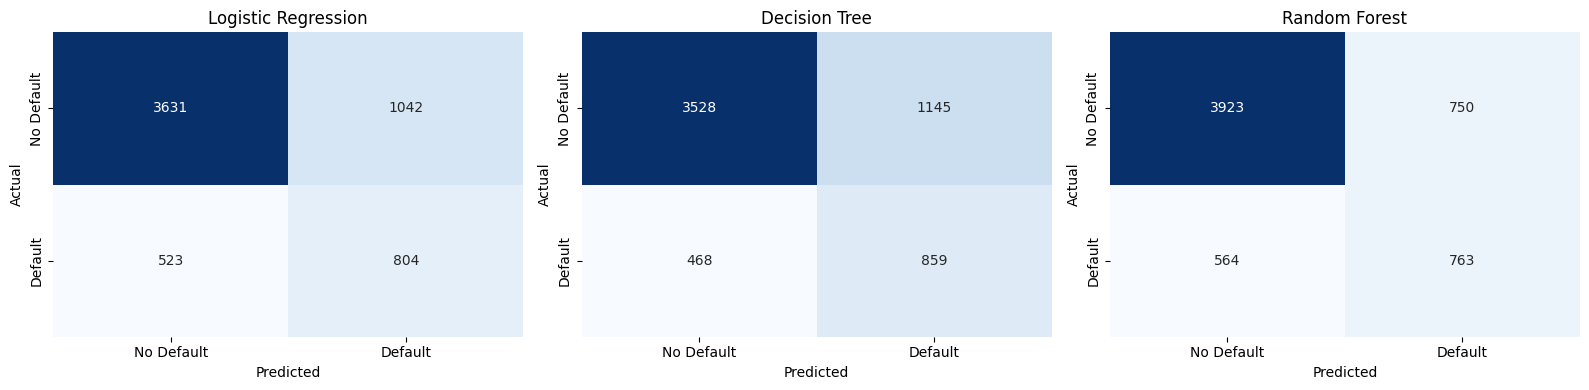

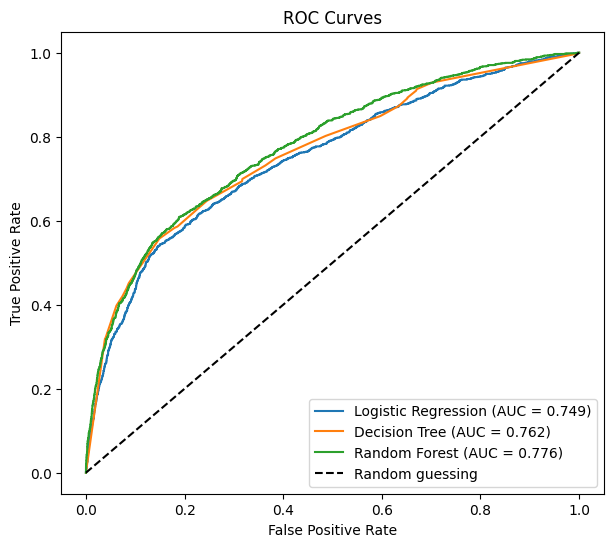

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# 1. Metrics table (for the Default class = 1)
rows = []
for name, r in results.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, r['pred']),
        'Precision': precision_score(y_test, r['pred']),
        'Recall': recall_score(y_test, r['pred']),
        'F1-Score': f1_score(y_test, r['pred']),
        'ROC-AUC': roc_auc_score(y_test, r['proba'])
    })
metrics_df = pd.DataFrame(rows).set_index('Model').round(4)
print("--- Model Comparison (Test Set) ---")
display(metrics_df)

# 2. Detailed classification reports
for name, r in results.items():
    print(f"\n===== {name} =====")
    print(classification_report(y_test, r['pred'],
                                target_names=['No Default', 'Default']))

# 3. Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r['pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['No Default', 'Default'],
                yticklabels=['No Default', 'Default'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

# 4. ROC curves
plt.figure(figsize=(7, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r['proba'])
    auc = roc_auc_score(y_test, r['proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()

### Observation

**Results on the test set (6,000 clients, 1,327 of them real defaulters):**

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.7392 | 0.4355 | 0.6059 | 0.5068 | 0.7493 |
| Decision Tree | 0.7312 | 0.4286 | 0.6473 | 0.5158 | 0.7621 |
| Random Forest | 0.7810 | 0.5043 | 0.5750 | 0.5373 | 0.7765 |

- **Random Forest is the best overall model.** It has the highest F1-Score (0.5373), ROC-AUC (0.7765), Precision (0.5043) and Accuracy (0.7810).
- **The Decision Tree has the highest Recall (0.6473).** It found 859 of the 1,327 real defaulters, but it also wrongly flagged 1,145 good clients as risky.
- **Logistic Regression has the lowest F1-Score and ROC-AUC**, but it is still a reasonable baseline, and it is the simplest and easiest model to explain.
- **Accuracy is misleading here.** A model that predicts "No Default" for everyone would already get about 77.88% accuracy. Random Forest (78.10%) is only slightly above that, so Precision, Recall, F1-Score and ROC-AUC give a much better picture.
- **Precision vs Recall trade-off:** using `class_weight='balanced'` helped the models find more defaulters (Recall between 0.58 and 0.65), but the Precision is only between 0.43 and 0.50. In practice, roughly every second client flagged as risky is a false alarm.
- **ROC curves:** all three curves are clearly above the random-guessing line, so all models learned useful patterns. The curves are close to each other, with Random Forest slightly on top (AUC 0.776 vs 0.762 and 0.749).
- The differences between the models are small. The best choice depends on the business goal: a bank that wants to catch as many defaulters as possible may prefer a higher Recall, while a bank that wants to avoid rejecting good clients may prefer a higher Precision.

## Step 8: Save the Model
We save the best model (Random Forest) so it can be reused later without training again. We also save the `StandardScaler` and the list of feature names, because new data must be prepared in exactly the same way as the training data. The files are saved with `joblib` and then reloaded once to check that they work correctly.

In [8]:
import joblib

# Save the best model, the scaler and the feature names
joblib.dump(rand_forest, 'credit_scoring_random_forest.pkl', compress=3)
joblib.dump(scaler, 'credit_scoring_scaler.pkl')
joblib.dump(list(X.columns), 'credit_scoring_features.pkl')
print("Files saved successfully!")

# Reload the model and check that it gives the same results
loaded_model = joblib.load('credit_scoring_random_forest.pkl')
loaded_proba = loaded_model.predict_proba(X_test)[:, 1]
print("ROC-AUC of the reloaded model:", round(roc_auc_score(y_test, loaded_proba), 4))

# Download the files to your computer
from google.colab import files
files.download('credit_scoring_random_forest.pkl')
files.download('credit_scoring_scaler.pkl')
files.download('credit_scoring_features.pkl')

Files saved successfully!
ROC-AUC of the reloaded model: 0.7765


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 9: Conclusion

In this project we built a credit scoring model that predicts whether a credit card client will default on the next payment. We used the "Default of Credit Card Clients" dataset (30,000 clients) and followed a complete machine learning workflow: data exploration, cleaning, feature engineering, scaling, model training and evaluation.

**What we did**
- Cleaned the undocumented category values in `EDUCATION` and `MARRIAGE` and dropped the `ID` column.
- Created 9 new features from the financial history, such as credit utilization, payment ratio, number of late months and maximum delay.
- Trained Logistic Regression, Decision Tree and Random Forest with `class_weight='balanced'` to handle the imbalanced target (about 22% defaulters).
- Evaluated all models using Precision, Recall, F1-Score and ROC-AUC on a held-out test set.

**Key findings**
- **Random Forest performed best overall**, with an F1-Score of 0.5373 and a ROC-AUC of 0.7765.
- The Decision Tree gave the highest Recall (0.6473), and Logistic Regression was the simplest baseline.
- In the correlation analysis, the delay-related engineered features (`NUM_LATE_MONTHS`, `MAX_DELAY`, `AVG_PAY_STATUS`) had the strongest relationship with default. This shows that **payment history is the strongest signal of credit risk**.
- Accuracy alone is misleading on imbalanced data, so the other metrics were essential.

**Limitations and future improvements**
- Precision for the default class is only about 0.43 to 0.50, so many flagged clients are false alarms.
- The models used mostly default settings. Hyperparameter tuning (for example with GridSearchCV) could improve them.
- Other ideas to try: adjusting the decision threshold, resampling methods such as SMOTE, and gradient boosting models such as XGBoost or LightGBM.
- The data comes from one bank in Taiwan in 2005, so the model may not work as well on other populations without retraining.